In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
import joblib

In [16]:
LOOKBACK = 30
HORIZON = 1

TRAIN_END = "2022-12-31"
VAL_END = "2023-12-31"

BATCH_SIZE = 64
EPOCHS = 40
LEARNING_RATE = 0.0005

In [17]:
df = pd.read_csv("../data/processed/nvda_clean.csv", index_col=0, parse_dates=True)

df.head()

,close
Date,
2018-01-02,4.928532
2018-01-03,5.252899
2018-01-04,5.280590
2018-01-05,5.325338
2018-01-08,5.488509


In [18]:
train = df.loc[:TRAIN_END]
val   = df.loc[TRAIN_END:VAL_END].iloc[1:]

print("Train:", train.shape)
print("Val:  ", val.shape)

Train: (1259, 1)
Val:   (249, 1)


In [19]:
scaler = StandardScaler()

# Ajusta SOMENTE no treino
train_scaled = scaler.fit_transform(train[["close"]])
val_scaled   = scaler.transform(val[["close"]])

In [20]:
def create_windows(values, lookback, horizon=1):
    X, y = [], []
    for i in range(len(values) - lookback - horizon + 1):
        X.append(values[i : i + lookback])
        y.append(values[i + lookback + horizon - 1])
    return np.array(X), np.array(y)

In [21]:
X_train, y_train = create_windows(train_scaled, LOOKBACK, HORIZON)
X_val, y_val     = create_windows(val_scaled, LOOKBACK, HORIZON)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:  ", X_val.shape)
print("y_val:  ", y_val.shape)

X_train: (1229, 30, 1)
y_train: (1229, 1)
X_val:   (219, 30, 1)
y_val:   (219, 1)


In [22]:
# (batch, seq_len, features)
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val   = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)

In [23]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)

In [24]:
train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [25]:
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, num_layers=1):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        last_output = lstm_out[:, -1, :]
        return self.fc(last_output)

In [26]:
model = LSTMModel()

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

model

LSTMModel(
  (lstm): LSTM(1, 50, batch_first=True)
  (fc): Linear(in_features=50, out_features=1, bias=True)
)

In [28]:
#outputs = model(X_batch)
#loss = criterion(outputs, y_batch)

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    # Treino
    model.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    # Validação
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item()

    val_loss /= len(val_loader)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [1/40] Train Loss: 0.7409 | Val Loss: 12.3094
Epoch [2/40] Train Loss: 0.3909 | Val Loss: 6.9569
Epoch [3/40] Train Loss: 0.1109 | Val Loss: 6.2999
Epoch [4/40] Train Loss: 0.0661 | Val Loss: 5.2290
Epoch [5/40] Train Loss: 0.0412 | Val Loss: 4.2343
Epoch [6/40] Train Loss: 0.0292 | Val Loss: 3.5441
Epoch [7/40] Train Loss: 0.0214 | Val Loss: 3.0630
Epoch [8/40] Train Loss: 0.0196 | Val Loss: 2.7388
Epoch [9/40] Train Loss: 0.0176 | Val Loss: 2.4771
Epoch [10/40] Train Loss: 0.0173 | Val Loss: 2.3216
Epoch [11/40] Train Loss: 0.0152 | Val Loss: 2.1837
Epoch [12/40] Train Loss: 0.0150 | Val Loss: 1.9549
Epoch [13/40] Train Loss: 0.0147 | Val Loss: 1.8201
Epoch [14/40] Train Loss: 0.0139 | Val Loss: 1.7006
Epoch [15/40] Train Loss: 0.0127 | Val Loss: 1.6202
Epoch [16/40] Train Loss: 0.0125 | Val Loss: 1.4823
Epoch [17/40] Train Loss: 0.0112 | Val Loss: 1.4469
Epoch [18/40] Train Loss: 0.0111 | Val Loss: 1.3066
Epoch [19/40] Train Loss: 0.0106 | Val Loss: 1.2775
Epoch [20/40] Train 

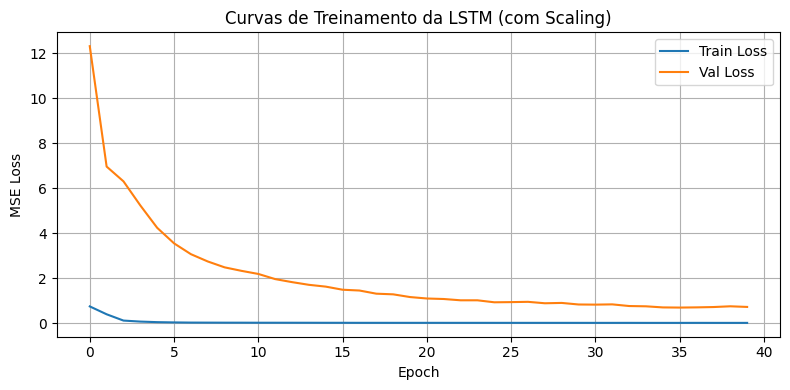

In [29]:
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Curvas de Treinamento da LSTM (com Scaling)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
torch.save(model.state_dict(), "../data/models/lstm_nvda.pt")
joblib.dump(scaler, "../data/models/scaler_nvda.pkl")

print("Modelo e scaler salvos com sucesso!")

Modelo e scaler salvos com sucesso!
